# Logistic regression: financial hit or bust
Using only information available before release, predict whether a movie earns at least 2.5 times its production budget. Predict **`success`** from the engineered inputs in `../../data/model_data_success_2026-11-04.csv`.

- **1 — Hit:** reported revenue is at least 2.5 times budget.
- **0 — Bust:** reported revenue is below that benchmark.

These are project labels, not audited profit/loss. A regularized linear classifier: a simple, interpretable starting point. All classifiers use the same chronological split and validation folds. Initial and training-validation-selected settings are compared below.


Section 4 validates/tunes settings without using the later test data to choose them.

The predictors include directors' smoothed earlier-year rating history, which uses retrospective ratings on strictly earlier films. The target movie's rating is still excluded from predictors.

`log_budget` is the base-10 log of reported production budget. Current revenue and outcomes are excluded from predictors.

## Tuning controls — edit here first

1. Edit the controls in the next cell.
2. **Save the notebook and Run All** so every result uses the same settings.
3. Review the validation table, then the later-test table. Do not repeatedly tune against test scores.

| What you want to change | Control |
|---|---|
| Original model or a setting not searched | `MODEL_SETTINGS` |
| Trial values for model settings | `PARAM_GRID` (lists). These override `MODEL_SETTINGS` during search |
| Which score selects `C`, `class_weight`, and `l1_ratio` (Section 4) | `TUNING_METRIC` |
| Which score selects the cutoff (Section 4b) | `THRESHOLD_METRIC` |
| Feature groups to compare | `FEATURE_GROUPS_TO_COMPARE` |
| Required mean validation hit precision | `MIN_VALIDATION_PRECISION` (currently 0.70) |
| Final hit thresholds to test | `THRESHOLDS` |
| Date boundary and number of validation folds | `CUTOFF_DATE`, `N_VALIDATION_SPLITS`. Keep consistent across models |
| Fold counts compared in Section 4c | `FOLD_COUNTS_TO_COMPARE` |

Smaller `C` shrinks coefficients more. `l1_ratio` sets the penalty type (0 = ridge, 0.5 = elastic net, 1 = lasso). `class_weight="balanced"` changes class emphasis and does not guarantee higher precision.

**Example:** Try the `C`, `class_weight`, or `l1_ratio` lists in `PARAM_GRID`. Change the required precision with `MIN_VALIDATION_PRECISION`, not by editing validation code. Keep parameter key names unchanged when editing trial values.

In [1]:
# EDIT THIS CELL, then save and Run All. Do not change settings in later cells.
DATA_FILE = "../../data/model_data_success_2026-11-04.csv"
CUTOFF_DATE = "2017-11-18"  # Change consistently across models for a fair comparison.
N_VALIDATION_SPLITS = 3     # Expanding chronological folds inside training.
FOLD_COUNTS_TO_COMPARE = [3, 5]  # Section 4c compares these. The final model still uses N_VALIDATION_SPLITS.

# Fixed original-model settings. Grid values below override these during a search.
MODEL_SETTINGS = {'C': 1.0, 'max_iter': 3000, 'random_state': 42, 'solver': 'saga'}  # saga supports ridge, lasso, and elastic net

# CHANGE THESE LISTS to try model settings. More values mean a longer run.
PARAM_GRID = {'classifier__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
              'classifier__class_weight': [None, 'balanced'],
              'classifier__l1_ratio': [0.0, 0.5, 1.0]}   # 0 = ridge, 0.5 = elastic net, 1 = lasso
TUNING_METRIC = "ROC_AUC"      # Picks C, class_weight, and l1_ratio in Section 4. ROC AUC does not depend on the cutoff.
THRESHOLD_METRIC = "Hit_F1"    # Picks the cutoff among eligible candidates in Section 4b.
# Hit_F1 balances hit precision and recall. The precision guard below is separate.

# Remove a group to skip it. Keep All features for the reference comparison.
FEATURE_GROUPS_TO_COMPARE = [
    "Movie characteristics", "+ Director history", "+ Actor history", "All features",
]
assert "All features" in FEATURE_GROUPS_TO_COMPARE

# Goal and threshold search. This is VALIDATION precision, not a test guarantee.
MIN_VALIDATION_PRECISION = 0.70
THRESHOLDS = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60,
              0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
BASE_THRESHOLD = 0.5  # Cutoff for the initial and settings-only models and for the 0.5-cutoff hit scores in Sections 4, 4d, and 7.
assert 0 <= MIN_VALIDATION_PRECISION <= 1
assert THRESHOLDS and all(0 < value < 1 for value in THRESHOLDS)

assert isinstance(N_VALIDATION_SPLITS, int) and N_VALIDATION_SPLITS >= 2

assert set(FEATURE_GROUPS_TO_COMPARE) <= {"Movie characteristics", "+ Director history", "+ Actor history", "All features"}


In [2]:
# Packages for data handling, plotting, preprocessing, models, and metrics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.linear_model import LogisticRegression

# Load the model table and sort it by release date for the time-based split and folds
movies = pd.read_csv(DATA_FILE, parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
# Each movie appears once, every movie has a date, and the target is only 0 or 1
assert movies["tmdb_id"].is_unique and movies["release_date"].notna().all()
assert movies["success"].isin([0, 1]).all()
print(f"Loaded {len(movies):,} movies | Target: success")

Loaded 6,919 movies | Target: success


## 1. Select predictors
Use movie characteristics and earlier history. Exclude both `success` and `vote_average`, identifiers, and current-movie financial outcomes. `release_year` and `n_genres` stay in the data but are not predictors, because the test years fall after every training year and `n_genres` is almost exactly the sum of the genre flags. `backfill_unavailable` is also left out because it flags only 26 training movies and no test movies. The partner features `franchise_prior_films_log1p`, `dir_prior_rated_films_log1p`, `dir_years_active_log1p`, and `dir_no_rating_history` are left out because each repeats information in a feature that is kept, as shown in Sections 2 and 4d. Certification and month are categorical. Binary flags remain 0/1.

In [3]:
ID_COLUMNS = ["tmdb_id", "imdb_id", "title_tmdb", "release_date"]
TARGET_COLUMNS = ["success", "vote_average"]
# Kept in the data but not used as predictors. The test years fall after every training year (release_year),
# n_genres is almost exactly the sum of the genre flags, and backfill_unavailable flags only 26 training movies and no test movies.
# The partner features repeat information in a feature that was kept (Section 2 correlations, tested in Section 4d).
PARTNER_NUMERIC_FEATURES = ["franchise_prior_films_log1p", "dir_prior_rated_films_log1p", "dir_years_active_log1p"]
PARTNER_BINARY_FEATURES = ["dir_no_rating_history"]
EXCLUDED_COLUMNS = ["release_year", "n_genres", "backfill_unavailable"] + PARTNER_NUMERIC_FEATURES + PARTNER_BINARY_FEATURES
NUMERIC_FEATURES = [
    "runtime", "log_budget", "imdb_director_count",
    "dir_prior_success_rate_smoothed", "dir_prior_rating_smoothed",
    "dir_prior_films_log1p",
    "dir_prior_known_films_log1p",
    "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = [
    "is_sequel", "is_english", "dir_first_film", "dir_no_track_record",
] + [column for column in movies if column.startswith("genre_")]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))
assert set(movies) == set(ID_COLUMNS + TARGET_COLUMNS + EXCLUDED_COLUMNS + FEATURE_COLUMNS)
assert not set(ID_COLUMNS + TARGET_COLUMNS + EXCLUDED_COLUMNS) & set(FEATURE_COLUMNS)
assert not {"budget", "revenue", "revenue_to_budget", "popularity", "vote_count"} & set(FEATURE_COLUMNS)
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()

X = movies[FEATURE_COLUMNS].copy()
# String conversion is a fixed type conversion, not a learned transformation.
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies["success"].astype(int).copy()
print(f"Predictors: {len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical, {len(BINARY_FEATURES)} binary")

Predictors: 9 numeric, 2 categorical, 22 binary


In [4]:
# Display all feature options and the target options
# Show the target options with their type and number of distinct values
print("Target options:", len(TARGET_COLUMNS))
for column in TARGET_COLUMNS:
    print(" ", column, "| type:", movies[column].dtype, "| distinct values:", movies[column].nunique())

# Show the columns that stay in the data but are not used as predictors
print("\nNot used as predictors:", EXCLUDED_COLUMNS)

# Show the feature options with their type, distinct values, and missing values
print("\nFeature options:", len(FEATURE_COLUMNS))
feature_table = pd.DataFrame({
    "Type": movies[FEATURE_COLUMNS].dtypes.astype(str),
    "Distinct values": movies[FEATURE_COLUMNS].nunique(),
    "Missing values": movies[FEATURE_COLUMNS].isna().sum(),
})
display(feature_table)

Target options: 2
  success | type: int64 | distinct values: 2
  vote_average | type: float64 | distinct values: 1779

Not used as predictors: ['release_year', 'n_genres', 'backfill_unavailable', 'franchise_prior_films_log1p', 'dir_prior_rated_films_log1p', 'dir_years_active_log1p', 'dir_no_rating_history']

Feature options: 33


,Type,Distinct values,Missing values
runtime,float64,142,3
log_budget,float64,703,0
imdb_director_count,int64,10,0
dir_prior_success_rate_smoothed,float64,1132,0
dir_prior_rating_smoothed,float64,4174,0
dir_prior_films_log1p,float64,66,0
dir_prior_known_films_log1p,float64,30,0
lead_actor_films_5yr_backfilled_log1p,float64,21,0
company_films_5yr_log1p,float64,82,0
us_certification,str,6,0


## 2. Split earlier movies from later movies
Train on approximately the earliest 80% of movies and test on the later movies. The cutoff date of 2017-11-18 places 5,535 movies (80.0%) in training and 1,384 movies (20.0%) in testing, and movies released on the same date always fall on the same side. Inspect class balance before interpreting accuracy. Hits make up 36.7% of training movies (2,029 of 5,535) and 34.3% of test movies (475 of 1,384).

In [5]:
# Movies released before the cutoff train the model, and movies on or after it are the test set
cutoff = pd.Timestamp(CUTOFF_DATE)
train_mask = movies["release_date"].lt(cutoff)
test_mask = ~train_mask
X_train, X_test = X.loc[train_mask].copy(), X.loc[test_mask].copy()
y_train, y_test = y.loc[train_mask].copy(), y.loc[test_mask].copy()
# Check that both sets are non-empty, every training movie is earlier, and no movie is in both
assert len(X_train) > 0 and len(X_test) > 0
assert movies.loc[train_mask, "release_date"].max() < movies.loc[test_mask, "release_date"].min()
assert set(movies.loc[train_mask, "tmdb_id"]).isdisjoint(movies.loc[test_mask, "tmdb_id"])
# Show the size and date range of each set
display(pd.DataFrame([
    ["Training", int(train_mask.sum()), movies.loc[train_mask, "release_date"].min(), movies.loc[train_mask, "release_date"].max()],
    ["Test", int(test_mask.sum()), movies.loc[test_mask, "release_date"].min(), movies.loc[test_mask, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))
# Both sets need hits and busts, so show how many of each
assert y_train.nunique() == 2 and y_test.nunique() == 2
class_balance = pd.DataFrame({
    "Training": y_train.value_counts().reindex([0, 1], fill_value=0),
    "Test": y_test.value_counts().reindex([0, 1], fill_value=0),
})
class_balance.index = pd.Index(["Bust (0)", "Hit (1)"], name="Outcome")
display(class_balance)

,Split,Movies,First release,Last release
0,Training,5535,1990-01-12,2017-11-17
1,Test,1384,2017-11-18,2025-12-25


,Training,Test
Outcome,,
Bust (0),3506,909
Hit (1),2029,475


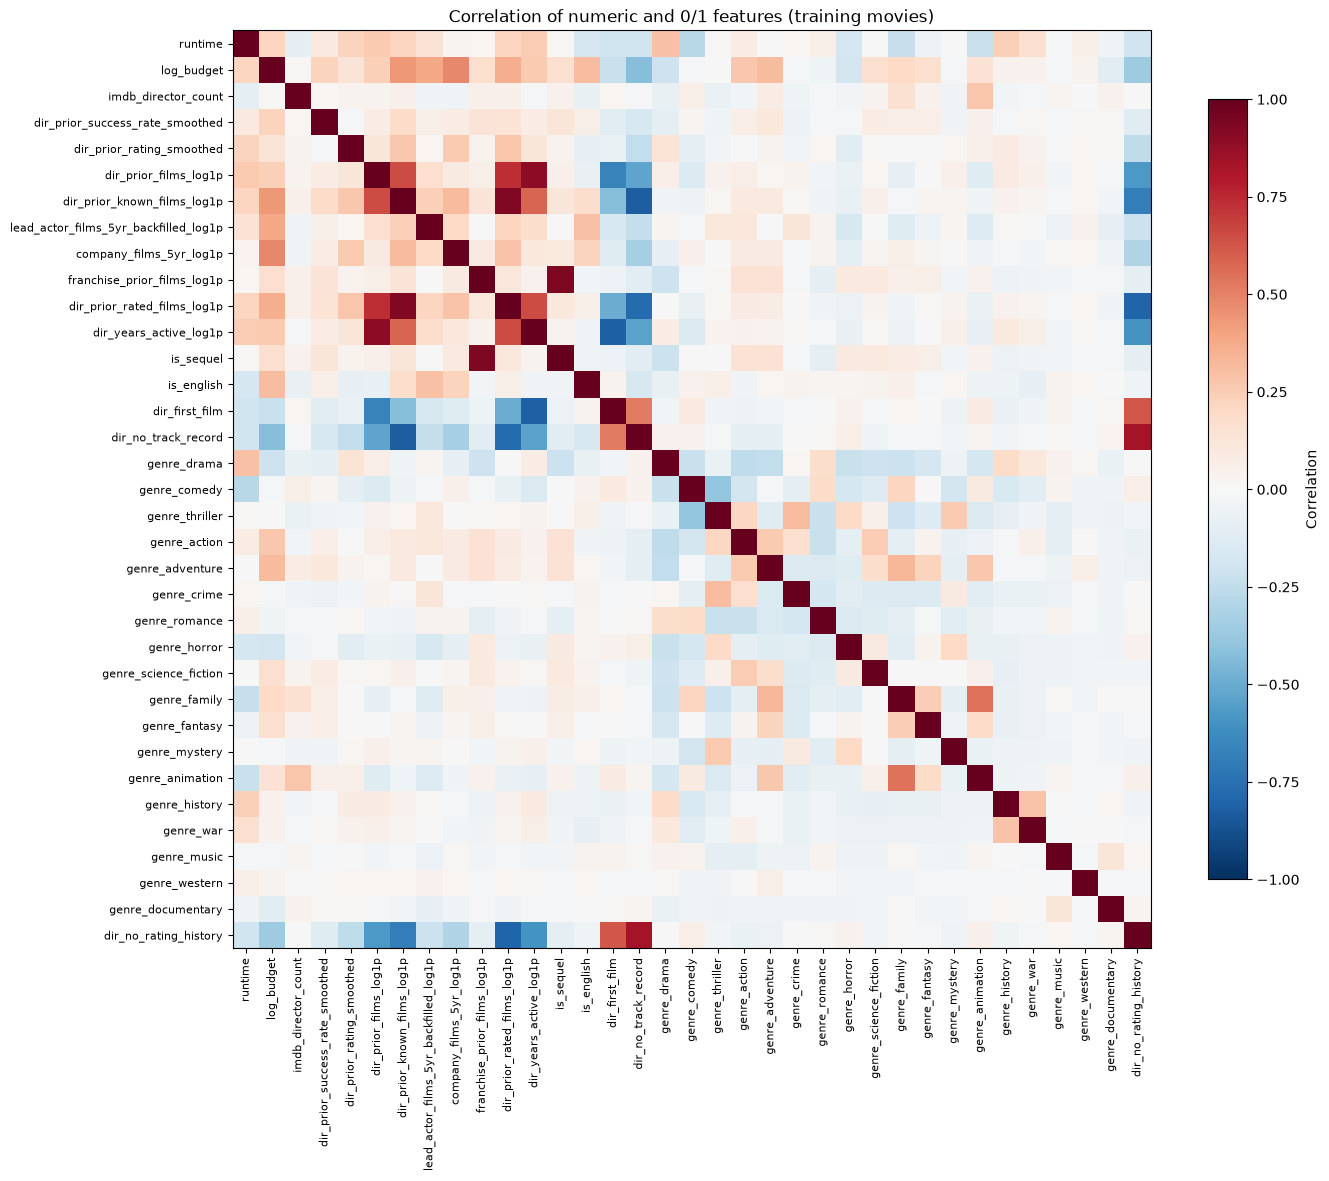

,Feature 1,Feature 2,Correlation
0,franchise_prior_films_log1p,is_sequel,0.930
1,dir_prior_known_films_log1p,dir_prior_rated_films_log1p,0.925
2,dir_prior_films_log1p,dir_years_active_log1p,0.894
3,dir_no_track_record,dir_no_rating_history,0.836
4,dir_prior_known_films_log1p,dir_no_track_record,-0.827
5,dir_years_active_log1p,dir_first_film,-0.815
6,dir_prior_rated_films_log1p,dir_no_rating_history,-0.801


In [6]:
# Correlation matrix of all numeric and 0/1 features, to find features that carry the same information
# Uses training movies only, so the test movies play no part in this decision
# us_certification and release_month are categories without a numeric order, so they are left out
# The partner features were later dropped, but they stay here because they are the evidence for that decision
correlation_columns = NUMERIC_FEATURES + PARTNER_NUMERIC_FEATURES + BINARY_FEATURES + PARTNER_BINARY_FEATURES
feature_correlation = movies.loc[train_mask, correlation_columns].corr()

# Draw the matrix as a heatmap
fig, ax = plt.subplots(figsize=(14, 12))
image = ax.imshow(feature_correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_columns)))
ax.set_xticklabels(correlation_columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(correlation_columns)))
ax.set_yticklabels(correlation_columns, fontsize=8)
fig.colorbar(image, ax=ax, label="Correlation", shrink=0.8)
ax.set_title("Correlation of numeric and 0/1 features (training movies)")
plt.tight_layout()
plt.show()

# List every pair of features once
correlation_pairs = []
for row in range(len(correlation_columns)):
    for col in range(row + 1, len(correlation_columns)):
        correlation_pairs.append({
            "Feature 1": correlation_columns[row],
            "Feature 2": correlation_columns[col],
            "Correlation": feature_correlation.iloc[row, col],
        })

# Sort by strength, so strong negative correlations count as well, and show the top 7
top_correlations = pd.DataFrame(correlation_pairs)
top_correlations["Strength"] = top_correlations["Correlation"].abs()
top_correlations = top_correlations.sort_values("Strength", ascending=False).head(7).reset_index(drop=True)
display(top_correlations[["Feature 1", "Feature 2", "Correlation"]].round(3))

### Correlated features removed
The correlation matrix above shows that four pairs of features carry largely the same information, with correlations of 0.930 for `is_sequel` and `franchise_prior_films_log1p`, 0.925 for `dir_prior_known_films_log1p` and `dir_prior_rated_films_log1p`, 0.894 for `dir_prior_films_log1p` and `dir_years_active_log1p`, and 0.836 for `dir_no_track_record` and `dir_no_rating_history`. Because redundant predictors divide their effect across correlated coefficients and make individual odds ratios unreliable, we retain one feature from each pair. Section 4d tests this decision on the validation folds, where retaining `is_sequel`, `dir_prior_known_films_log1p`, `dir_prior_films_log1p`, and `dir_no_track_record` yields a mean validation ROC AUC of 0.674, compared with 0.673 when all four partners are also included, a difference well within the fold-to-fold standard deviation of approximately 0.03. Since the validation scores do not distinguish between the two features of each pair, we selected the retained features for interpretability, which allows the odds ratios to communicate each effect clearly to studio decision-makers.

## 3. Fit the classifier and the two baselines
Build the original reference model with **`MODEL_SETTINGS` in the top Tuning controls cell**. Change searched values in `PARAM_GRID` where available. Values in that grid override the original settings during search.

The two baselines use no features. The majority baseline always predicts bust and is the score to beat on accuracy, while the always-hit baseline predicts hit for every movie and is the score to beat on hit F1. Imputation, scaling, and categorical encoding are fitted on training data only. Binary flags pass through unchanged. One-hot encoding uses R/NC-17 as the reference certification, because it is the largest group, and January as the reference month. No current-movie outcome is a predictor.

In [7]:
def make_classifier(columns):
    """Fresh preprocessing and classification for each feature set and split."""
    numeric = [column for column in NUMERIC_FEATURES + PARTNER_NUMERIC_FEATURES if column in columns]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in BINARY_FEATURES + PARTNER_BINARY_FEATURES if column in columns]
    assert set(numeric + categorical + binary) == set(columns)
    # Reference group for each category: R/NC-17 is the largest certification group, and January is month 1
    reference_groups = {"us_certification": "R/NC-17", "release_month": "1"}
    drop_groups = []
    for column in categorical:
        drop_groups.append(reference_groups[column])
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop=drop_groups, handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
        ("binary", "passthrough", binary),
    ])
    return Pipeline([
        ("preprocessor", preprocessing),
        ("classifier", LogisticRegression(**MODEL_SETTINGS)),
    ])

# Initial model: all predictors, MODEL_SETTINGS, fitted on the training movies, scored at the 0.5 cutoff
initial_model = make_classifier(FEATURE_COLUMNS)
initial_model.fit(X_train, y_train)
initial_train_probability = initial_model.predict_proba(X_train)[:, list(initial_model.classes_).index(1)]
initial_test_probability = initial_model.predict_proba(X_test)[:, list(initial_model.classes_).index(1)]
initial_train_prediction = (initial_train_probability >= BASE_THRESHOLD).astype(int)
initial_test_prediction = (initial_test_probability >= BASE_THRESHOLD).astype(int)

# Majority baseline: labels every movie a bust, which is the no-skill score to beat on accuracy
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_prediction = baseline.predict(np.zeros((len(y_test), 1)))
baseline_probability = baseline.predict_proba(np.zeros((len(y_test), 1)))[:, list(baseline.classes_).index(1)]
print("Majority-class baseline prediction:", int(y_train.mode().iloc[0]))

# Always-hit baseline: labels every movie a hit, which is the no-skill score to beat on hit F1
always_hit_baseline = DummyClassifier(strategy="constant", constant=1)
always_hit_baseline.fit(np.zeros((len(y_train), 1)), y_train)
always_hit_prediction = always_hit_baseline.predict(np.zeros((len(y_test), 1)))
always_hit_probability = always_hit_baseline.predict_proba(np.zeros((len(y_test), 1)))[:, list(always_hit_baseline.classes_).index(1)]
print("Always-hit baseline prediction:", int(always_hit_prediction[0]))

Majority-class baseline prediction: 0
Always-hit baseline prediction: 1


## 4. Validation and tuning: ROC AUC
Search the existing estimator grid using three expanding chronological folds entirely within the earlier training period. Preprocessing is fitted anew for each candidate/fold. Select by **ROC AUC**, which measures how well the model ranks hits above busts at every cutoff, and show hit F1, hit precision, and hit recall alongside accuracy, balanced accuracy, macro F1, and average precision.

ROC AUC does not depend on the cutoff, so it compares settings without rewarding a setting that simply labels more movies as hits. Section 4b adds the precision emphasis by requiring a candidate's mean validation hit precision to meet `MIN_VALIDATION_PRECISION`, then maximizing `THRESHOLD_METRIC` (hit F1) among eligible candidates. F1 gives precision and recall equal weight. It is not precision-weighted. The hit F1, precision, and recall shown in this section use threshold 0.5. Threshold selection follows below.

Edit `PARAM_GRID` before running. The later test data does not select settings. These folds have already been used in development, so selection scores are exploratory and not independent performance estimates.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings. Do not redefine them here.**

### Why three validation folds
We use three expanding chronological folds instead of five because each fold trains on earlier movies and validates on the next block of movies, so adding folds shrinks both the validation blocks and the first training set. With three folds, each validation block holds roughly 1,400 movies (1,427, 1,384, and 1,395 in the table below), which provides more movies per score than five folds would, and the first fold still trains on 1,329 movies released from 1990 to 1999. A smaller first training set would consist mostly of 1990–1994 releases, whose history features are incomplete because our data begins in 1990. In the feature engineering notebook, 71% of 1990–1994 movies have no director track record, compared with 33% to 43% in later periods. Section 4c tests this choice as a tracked experiment by repeating the selection with both three and five folds.

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

# Three expanding validation windows entirely within the outer training period.
tuning_dates = movies.loc[train_mask, "release_date"]
assert tuning_dates.index.equals(X_train.index)
unique_tuning_dates = np.sort(tuning_dates.unique())
tuning_splits = []
tuning_periods = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_tuning_dates), 1):
    fit_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[earlier]).to_numpy())
    validation_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[later]).to_numpy())
    assert tuning_dates.iloc[fit_positions].max() < tuning_dates.iloc[validation_positions].min()
    assert set(fit_positions).isdisjoint(validation_positions)
    tuning_splits.append((fit_positions, validation_positions))
    tuning_periods.append({
        "Fold": fold, "Training movies": len(fit_positions), "Validation movies": len(validation_positions),
        "Training ends": tuning_dates.iloc[fit_positions].max().date(),
        "Validation starts": tuning_dates.iloc[validation_positions].min().date(),
        "Validation ends": tuning_dates.iloc[validation_positions].max().date(),
    })
display(pd.DataFrame(tuning_periods))

SCORING = {
    "Hit_F1": make_scorer(f1_score, pos_label=1, zero_division=0),
    "Hit_precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "Hit_recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "Balanced_accuracy": "balanced_accuracy", "Accuracy": "accuracy",
    "Macro_F1": "f1_macro", "ROC_AUC": "roc_auc",
    "Average_precision": "average_precision",   # how well hits are ranked at the top, across every cutoff
}
for fit_positions, validation_positions in tuning_splits:
    assert y_train.iloc[fit_positions].nunique() == 2
    assert y_train.iloc[validation_positions].nunique() == 2

search = GridSearchCV(
    estimator=make_classifier(FEATURE_COLUMNS), param_grid=PARAM_GRID,
    scoring=SCORING, refit=TUNING_METRIC, cv=tuning_splits,
    n_jobs=1, return_train_score=True, error_score="raise",
)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
tuning_results = pd.DataFrame({
    "Settings": cv_results["params"].map(lambda params: {key.split("__", 1)[1]: value for key, value in params.items()}),
})
for metric in SCORING:
    tuning_results["Training " + metric] = cv_results["mean_train_" + metric]
    tuning_results["Validation " + metric] = cv_results["mean_test_" + metric]
tuning_results["Validation score std"] = cv_results["std_test_" + TUNING_METRIC]
tuning_results = tuning_results.sort_values("Validation " + TUNING_METRIC, ascending=False, kind="stable")
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    display(tuning_results.reset_index(drop=True).round(4))
print("Selection metric:", TUNING_METRIC)
print("Selected settings:", search.best_params_)
# GridSearchCV already refits the chosen pipeline on the full outer training period.
model = search.best_estimator_
assert set(FEATURE_COLUMNS).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
# Keep 0.5 fixed: this search tunes estimator settings, not the threshold.
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= BASE_THRESHOLD).astype(int)
test_prediction = (test_probability >= BASE_THRESHOLD).astype(int)
assert np.isfinite(test_probability).all()
assert ((test_probability >= 0) & (test_probability <= 1)).all()

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,1329,1427,1999-12-03,1999-12-10,2006-11-01
1,2,2756,1384,2006-11-01,2006-11-02,2012-03-12
2,3,4140,1395,2012-03-12,2012-03-14,2017-11-17


,Settings,Training Hit_F1,Validation Hit_F1,Training Hit_precision,Validation Hit_precision,Training Hit_recall,Validation Hit_recall,Training Balanced_accuracy,Validation Balanced_accuracy,Training Accuracy,Validation Accuracy,Training Macro_F1,Validation Macro_F1,Training ROC_AUC,Validation ROC_AUC,Training Average_precision,Validation Average_precision,Validation score std
0,"{'C': 10.0, 'class_weight': 'balanced', 'l1_ratio': 0.5}",0.5484,0.5612,0.4846,0.4977,0.6316,0.6433,0.6417,0.6255,0.6448,0.6227,0.6278,0.6141,0.6986,0.6745,0.5286,0.5500,0.0236
1,"{'C': 10.0, 'class_weight': 'balanced', 'l1_ratio': 0.0}",0.5486,0.5607,0.4849,0.4973,0.6316,0.6428,0.6418,0.6251,0.6451,0.6222,0.6281,0.6136,0.6985,0.6745,0.5288,0.5501,0.0235
2,"{'C': 10.0, 'class_weight': 'balanced', 'l1_ratio': 1.0}",0.5488,0.5612,0.4853,0.4977,0.6316,0.6433,0.6421,0.6255,0.6454,0.6227,0.6284,0.6141,0.6986,0.6745,0.5286,0.5499,0.0237
3,"{'C': 100.0, 'class_weight': 'balanced', 'l1_ratio': 1.0}",0.5487,0.5611,0.4849,0.4975,0.6320,0.6433,0.6419,0.6254,0.6450,0.6224,0.6281,0.6139,0.6986,0.6745,0.5288,0.5501,0.0236
4,"{'C': 100.0, 'class_weight': 'balanced', 'l1_ratio': 0.5}",0.5487,0.5607,0.4849,0.4973,0.6320,0.6428,0.6419,0.6251,0.6450,0.6222,0.6281,0.6136,0.6986,0.6745,0.5288,0.5501,0.0236
5,"{'C': 100.0, 'class_weight': 'balanced', 'l1_ratio': 0.0}",0.5487,0.5607,0.4849,0.4973,0.6320,0.6428,0.6419,0.6251,0.6450,0.6222,0.6281,0.6136,0.6986,0.6745,0.5288,0.5501,0.0236
6,"{'C': 1.0, 'class_weight': 'balanced', 'l1_ratio': 0.0}",0.5494,0.5603,0.4857,0.4966,0.6325,0.6428,0.6426,0.6245,0.6458,0.6215,0.6288,0.6130,0.6981,0.6744,0.5283,0.5499,0.0240
7,"{'C': 1.0, 'class_weight': 'balanced', 'l1_ratio': 0.5}",0.5487,0.5575,0.4858,0.4943,0.6304,0.6393,0.6422,0.6221,0.6459,0.6194,0.6287,0.6107,0.6980,0.6741,0.5284,0.5490,0.0249
8,"{'C': 1.0, 'class_weight': 'balanced', 'l1_ratio': 1.0}",0.5525,0.5570,0.4898,0.4946,0.6338,0.6374,0.6458,0.6219,0.6495,0.6196,0.6322,0.6108,0.6978,0.6740,0.5283,0.5486,0.0256
9,"{'C': 1.0, 'class_weight': None, 'l1_ratio': 0.0}",0.3548,0.4085,0.6017,0.6017,0.2519,0.3107,0.5826,0.5940,0.6876,0.6658,0.5743,0.5869,0.6970,0.6740,0.5309,0.5502,0.0243


Selection metric: ROC_AUC
Selected settings: {'classifier__C': 10.0, 'classifier__class_weight': 'balanced', 'classifier__l1_ratio': 0.5}


## 4b. Require 0.70 precision and judge hit F1
Use **`MIN_VALIDATION_PRECISION = 0.70`** as the mean hit precision requirement across the three chronological training-period folds. The group set 0.70 as the shared starting requirement for every success model, so that all models are selected and compared under the same rule. A lower precision requirement of 65% may be tested after that comparison and would then be applied to every model. Compare feature groups, original/selected settings, and probability thresholds 0.30–0.90. Among candidates meeting the requirement, maximize mean hit F1 (`THRESHOLD_METRIC`). Break ties with higher precision and proximity to threshold 0.5.

This is a validation precision requirement, not a guarantee of test precision. If no candidate qualifies, report the maximum observed validation precision and retain the original model only as a clearly labeled reference. Do not silently lower the target or use test outcomes to choose a threshold. F1 balances precision and recall equally. The separate guard supplies the precision emphasis. The always-hit baseline is printed below as the no-skill reference for hit F1. Reused folds give exploratory selection scores, not independent validation estimates.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings. Do not redefine them here.**

In [9]:
# Preserve the previous settings-only model for an honest before/after comparison.
settings_model = model
settings_train_probability = train_probability.copy()
settings_test_probability = test_probability.copy()
settings_train_prediction = train_prediction.copy()
settings_test_prediction = test_prediction.copy()

# Cumulative feature groups compared in this section
movie_features = (
    ["runtime", "log_budget", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p"]
company_franchise_features = ["company_films_5yr_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

# Settings to compare: the initial settings, plus the Section 4 winner if it differs
improvement_configurations = {"Initial settings": {}}
initial_parameters = initial_model.get_params()
if any(initial_parameters[key] != value for key, value in search.best_params_.items()):
    improvement_configurations["Settings selected in 4"] = search.best_params_.copy()

# Store only out-of-fold scores. No test rows enter fitting or selection.
selection_rows = []
for setting_name, parameters in improvement_configurations.items():
    for feature_name, columns in feature_versions.items():
        for fold, (fit_positions, validation_positions) in enumerate(tuning_splits, 1):
            candidate = make_classifier(columns).set_params(**parameters)
            candidate.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
            actual = y_train.iloc[validation_positions]
            assert actual.nunique() == 2
            probability = candidate.predict_proba(X_train.iloc[validation_positions])[:, list(candidate.classes_).index(1)]
            for threshold in sorted(set(THRESHOLDS + [BASE_THRESHOLD])):
                predicted = (probability >= threshold).astype(int)
                selection_rows.append({
                    "Feature set": feature_name, "Settings": setting_name, "Threshold": threshold, "Fold": fold,
                    "Balanced_accuracy": balanced_accuracy_score(actual, predicted),
                    "Accuracy": accuracy_score(actual, predicted),
                    "Macro_F1": f1_score(actual, predicted, average="macro", zero_division=0),
                    "Hit_F1": f1_score(actual, predicted, pos_label=1, zero_division=0),
                    "Hit_precision": precision_score(actual, predicted, pos_label=1, zero_division=0),
                    "ROC_AUC": roc_auc_score(actual, probability),
                    "Hit_recall": recall_score(actual, predicted, zero_division=0),
                })
selection_metrics = ["Hit_F1", "Hit_precision", "Hit_recall", "Balanced_accuracy", "Accuracy", "Macro_F1", "ROC_AUC"]
selection_keys = ["Feature set", "Settings", "Threshold"]
selection_fold_results = pd.DataFrame(selection_rows)
assert selection_fold_results.groupby(selection_keys)["Fold"].nunique().eq(N_VALIDATION_SPLITS).all()
assert np.isfinite(selection_fold_results[selection_metrics].to_numpy()).all()
improvement_summary = selection_fold_results.groupby(selection_keys, sort=False).agg(
    **{metric: (metric, "mean") for metric in selection_metrics},
    Score_std=(THRESHOLD_METRIC, "std"),
).reset_index()
# Precision guard: candidates must reach MIN_VALIDATION_PRECISION.
# The initial all-feature model at the 0.5 cutoff is kept as the fallback if no candidate qualifies.
original_validation = improvement_summary.loc[
    improvement_summary["Feature set"].eq("All features")
    & improvement_summary["Settings"].eq("Initial settings")
    & improvement_summary["Threshold"].eq(BASE_THRESHOLD)
]
assert len(original_validation) == 1
precision_floor = (
    float(original_validation.iloc[0]["Hit_precision"])
    if MIN_VALIDATION_PRECISION is None else float(MIN_VALIDATION_PRECISION)
)
assert 0 <= precision_floor <= 1
improvement_summary["Meets precision floor"] = improvement_summary["Hit_precision"].ge(precision_floor - 1e-12)
improvement_summary["Threshold distance"] = (improvement_summary["Threshold"] - 0.5).abs()
eligible_candidates = improvement_summary.loc[improvement_summary["Meets precision floor"] & improvement_summary["Threshold"].isin(THRESHOLDS)].sort_values(
    [THRESHOLD_METRIC, "Hit_precision", "Threshold distance"],
    ascending=[False, False, True], kind="stable",
).reset_index(drop=True)
precision_requirement_met = not eligible_candidates.empty
max_validation_precision = float(improvement_summary["Hit_precision"].max())
# Reference point: what always predicting hit scores on these same validation folds
always_hit_fold_f1 = []
for fit_positions, validation_positions in tuning_splits:
    always_hit_actual = y_train.iloc[validation_positions]
    always_hit_predicted = np.ones(len(always_hit_actual), dtype=int)
    always_hit_fold_f1.append(f1_score(always_hit_actual, always_hit_predicted, pos_label=1, zero_division=0))
print(f"Always-hit baseline mean validation hit F1: {np.mean(always_hit_fold_f1):.3f}")
print(f"Required mean validation hit precision: {precision_floor:.3f}")
print(f"Maximum observed mean validation precision: {max_validation_precision:.3f}")
print(f"Eligible candidates: {len(eligible_candidates)} of {len(improvement_summary)}")
if precision_requirement_met:
    with pd.option_context("display.max_columns", None):
        display(eligible_candidates.drop(columns=["Threshold distance"]).head(12).round(4))
    winner = eligible_candidates.iloc[0]
    assert winner["Hit_precision"] >= precision_floor - 1e-12
    selection_status = "Precision/F1-selected"
    print(f"Chosen mean validation precision: {winner['Hit_precision']:.3f}; hit F1: {winner['Hit_F1']:.3f}")
else:
    print("No candidate meets the configured validation precision. The original model is retained for reference, not presented as meeting the target.")
    display(improvement_summary.sort_values("Hit_precision", ascending=False).head(5).round(4))
    winner = original_validation.iloc[0]
    selection_status = "Original baseline (precision target infeasible)"
# Refit the selected candidate on all training movies and score it at the selected cutoff
selected_feature_set = winner["Feature set"]
selected_feature_columns = feature_versions[selected_feature_set]
selected_parameters = improvement_configurations[winner["Settings"]]
print("Selected feature group:", selected_feature_set)
print("Selected parameter configuration:", winner["Settings"], selected_parameters)
print("Mean selection score (not independent validation):", round(float(winner[THRESHOLD_METRIC]), 4))

model = make_classifier(selected_feature_columns).set_params(**selected_parameters)
model.fit(X_train, y_train)
assert set(selected_feature_columns).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
selected_threshold = float(winner["Threshold"])
print("Selected hit threshold:", selected_threshold)
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= selected_threshold).astype(int)
test_prediction = (test_probability >= selected_threshold).astype(int)
assert np.isfinite(test_probability).all()

Always-hit baseline mean validation hit F1: 0.547
Required mean validation hit precision: 0.700
Maximum observed mean validation precision: 0.917
Eligible candidates: 28 of 104


,Feature set,Settings,Threshold,Hit_F1,Hit_precision,Hit_recall,Balanced_accuracy,Accuracy,Macro_F1,ROC_AUC,Score_std,Meets precision floor
0,+ Director history,Initial settings,0.65,0.2052,0.7023,0.1208,0.5461,0.6517,0.4907,0.6735,0.0737,True
1,All features,Settings selected in 4,0.80,0.2014,0.7005,0.1178,0.5443,0.6496,0.4882,0.6745,0.0589,True
2,+ Director history,Settings selected in 4,0.80,0.1915,0.7018,0.1110,0.5420,0.6484,0.4831,0.6737,0.0534,True
3,+ Actor history,Initial settings,0.70,0.1564,0.7310,0.0879,0.5353,0.6460,0.4658,0.6740,0.0650,True
4,All features,Initial settings,0.70,0.1534,0.7177,0.0862,0.5339,0.6446,0.4639,0.6740,0.0638,True
5,+ Director history,Initial settings,0.70,0.1461,0.7201,0.0817,0.5324,0.6438,0.4602,0.6735,0.0639,True
6,All features,Settings selected in 4,0.85,0.1169,0.7252,0.0637,0.5242,0.6374,0.4442,0.6745,0.0194,True
7,+ Director history,Settings selected in 4,0.85,0.1154,0.7172,0.0628,0.5238,0.6371,0.4434,0.6737,0.0261,True
8,+ Actor history,Settings selected in 4,0.85,0.1151,0.7120,0.0628,0.5234,0.6367,0.4430,0.6742,0.0284,True
9,Movie characteristics,Initial settings,0.70,0.1089,0.7216,0.0591,0.5226,0.6366,0.4401,0.6612,0.0266,True


Chosen mean validation precision: 0.702; hit F1: 0.205
Selected feature group: + Director history
Selected parameter configuration: Initial settings {}
Mean selection score (not independent validation): 0.2052
Selected hit threshold: 0.65


**Conclusion for Section 4b.** Under the 0.70 requirement, 28 of the 104 candidates were eligible, and the highest mean validation hit F1 among them was 0.205, for the "+ Director history" feature group with the initial settings at a cutoff of 0.65, with a hit precision of 0.702 and a hit recall of 0.121. Raising the cutoff for the same group and settings to 0.70 increased precision to 0.720 but lowered recall to 0.082 and hit F1 to 0.146, so the 0.65 cutoff kept the most hits while still meeting the requirement. The next two candidates used the settings selected in Section 4 at a cutoff of 0.80, with hit F1 of 0.201 for all features and 0.192 for "+ Director history", so the initial settings and the "+ Director history" group led only narrowly, and the choice among these candidates is approximate. The winning initial settings are a ridge penalty with `C` = 1 and no class weighting, since `MODEL_SETTINGS` sets `C` = 1 and leaves `l1_ratio` and `class_weight` at their scikit-learn defaults of 0 (ridge) and None. The Section 4 search had preferred elastic net with `C` = 10 and balanced class weights, but ridge, elastic net, and lasso tied at a validation ROC AUC of 0.6745, so the penalty type made no measurable difference to ranking. The selected precision of 0.702 sits just above the requirement and varied across folds (standard deviation 0.074), and its hit F1 of 0.205 remains below the 0.547 of the always-hit baseline on the same folds, because the 0.70 requirement trades recall for precision.

### Precision requirement experiment: 0.60
This check applies a 0.60 precision requirement to the same Section 4b validation scores, so the experiment log can record what a lower requirement would have selected. Nothing is refitted, and the final model above still uses `MIN_VALIDATION_PRECISION`.

In [10]:
# Precision requirement experiment: the best candidate under a 0.60 requirement
# Uses the Section 4b validation scores. Nothing is refitted and the final model does not change
alternative_floor = 0.60

# Keep candidates whose mean validation precision reaches 0.60, at the cutoffs being tested
alternative_eligible = improvement_summary.loc[
    improvement_summary["Hit_precision"].ge(alternative_floor - 1e-12)
    & improvement_summary["Threshold"].isin(THRESHOLDS)
]

# Rank them the same way as Section 4b: highest hit F1, then higher precision, then closest to 0.5
alternative_eligible = alternative_eligible.sort_values(
    [THRESHOLD_METRIC, "Hit_precision", "Threshold distance"],
    ascending=[False, False, True], kind="stable",
)

# Show how many qualify and the best candidate
print(f"Eligible candidates at {alternative_floor:.2f}: {len(alternative_eligible)} of {len(improvement_summary)}")
display(alternative_eligible.head(1)[["Feature set", "Settings", "Threshold", "Hit_precision", "Hit_recall", "Hit_F1"]].round(4))

Eligible candidates at 0.60: 55 of 104


,Feature set,Settings,Threshold,Hit_precision,Hit_recall,Hit_F1
43,All features,Initial settings,0.5,0.6017,0.3107,0.4085


## 4c. Compare three and five validation folds
This experiment tests whether the selected model depends on the number of validation folds. For each fold count in `FOLD_COUNTS_TO_COMPARE`, the code rebuilds the expanding chronological folds, repeats the Section 4 settings search, and repeats the Section 4b selection of feature group, settings, and cutoff under the same precision requirement. Preprocessing is fitted anew for every fold, and only training movies are used, so the test movies play no part in this comparison. The final model below still uses `N_VALIDATION_SPLITS`.

In [11]:
# Compare fold counts using training movies only. Nothing here changes the final model above
fold_count_rows = []

for fold_count in FOLD_COUNTS_TO_COMPARE:
    # Step 1: build expanding folds by release date, the same way as Section 4
    count_splits = []
    for earlier_dates, later_dates in TimeSeriesSplit(n_splits=fold_count).split(unique_tuning_dates):
        count_fit = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[earlier_dates]).to_numpy())
        count_validation = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[later_dates]).to_numpy())
        assert tuning_dates.iloc[count_fit].max() < tuning_dates.iloc[count_validation].min()
        count_splits.append((count_fit, count_validation))

    # Step 2: repeat the Section 4 search of C, class_weight, and l1_ratio
    count_search = GridSearchCV(
        estimator=make_classifier(FEATURE_COLUMNS), param_grid=PARAM_GRID,
        scoring=SCORING, refit=TUNING_METRIC, cv=count_splits,
        n_jobs=1, error_score="raise",
    )
    count_search.fit(X_train, y_train)

    # Step 3: compare the initial settings with this search's winner, as in Section 4b
    count_settings = {"Initial settings": {}}
    settings_differ = False
    for key, value in count_search.best_params_.items():
        if initial_parameters[key] != value:
            settings_differ = True
    if settings_differ:
        count_settings["Settings selected in 4"] = count_search.best_params_.copy()

    # Step 4: score every feature group, settings choice, fold, and cutoff
    count_rows = []
    for count_setting_name, count_parameters in count_settings.items():
        for count_feature_name, count_columns in feature_versions.items():
            for count_fold, (count_fit, count_validation) in enumerate(count_splits, 1):
                count_model = make_classifier(count_columns).set_params(**count_parameters)
                count_model.fit(X_train.iloc[count_fit], y_train.iloc[count_fit])
                count_actual = y_train.iloc[count_validation]
                hit_column = list(count_model.classes_).index(1)
                count_probability = count_model.predict_proba(X_train.iloc[count_validation])[:, hit_column]
                for count_threshold in THRESHOLDS:
                    count_predicted = (count_probability >= count_threshold).astype(int)
                    count_rows.append({
                        "Feature set": count_feature_name, "Settings": count_setting_name,
                        "Threshold": count_threshold, "Fold": count_fold,
                        "Hit_F1": f1_score(count_actual, count_predicted, pos_label=1, zero_division=0),
                        "Hit_precision": precision_score(count_actual, count_predicted, pos_label=1, zero_division=0),
                        "Hit_recall": recall_score(count_actual, count_predicted, pos_label=1, zero_division=0),
                    })

    # Step 5: average across folds and apply the same precision rule and tie-breaks as Section 4b
    count_summary = pd.DataFrame(count_rows).groupby(["Feature set", "Settings", "Threshold"], sort=False)[
        ["Hit_F1", "Hit_precision", "Hit_recall"]
    ].mean().reset_index()
    count_summary["Threshold distance"] = (count_summary["Threshold"] - 0.5).abs()
    count_eligible = count_summary.loc[count_summary["Hit_precision"].ge(precision_floor - 1e-12)].sort_values(
        [THRESHOLD_METRIC, "Hit_precision", "Threshold distance"],
        ascending=[False, False, True], kind="stable",
    )

    # Step 6: record one row of results for this fold count
    best_index = count_search.best_index_
    smallest_validation = len(count_splits[0][1])
    for count_fit, count_validation in count_splits:
        if len(count_validation) < smallest_validation:
            smallest_validation = len(count_validation)
    short_settings = {}
    for key, value in count_search.best_params_.items():
        short_settings[key.split("__", 1)[1]] = value   # drop the "classifier__" prefix
    fold_count_row = {
        "Folds": fold_count,
        "Smallest training set": len(count_splits[0][0]),
        "Smallest validation block": smallest_validation,
        "Best settings (Section 4)": short_settings,
        "Validation ROC AUC": count_search.cv_results_["mean_test_ROC_AUC"][best_index],
        "ROC AUC std": count_search.cv_results_["std_test_ROC_AUC"][best_index],
        "Eligible candidates": len(count_eligible),
    }
    if len(count_eligible) > 0:
        count_winner = count_eligible.iloc[0]
        fold_count_row["Selected feature group"] = count_winner["Feature set"]
        fold_count_row["Selected settings"] = count_winner["Settings"]
        fold_count_row["Selected cutoff"] = count_winner["Threshold"]
        fold_count_row["Validation hit precision"] = count_winner["Hit_precision"]
        fold_count_row["Validation hit recall"] = count_winner["Hit_recall"]
        fold_count_row["Validation hit F1"] = count_winner["Hit_F1"]
    fold_count_rows.append(fold_count_row)

fold_count_comparison = pd.DataFrame(fold_count_rows)
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    display(fold_count_comparison.round(4))

,Folds,Smallest training set,Smallest validation block,Best settings (Section 4),Validation ROC AUC,ROC AUC std,Eligible candidates,Selected feature group,Selected settings,Selected cutoff,Validation hit precision,Validation hit recall,Validation hit F1
0,3,1329,1384,"{'C': 10.0, 'class_weight': 'balanced', 'l1_ratio': 0.5}",0.6745,0.0236,28,+ Director history,Initial settings,0.65,0.7023,0.1208,0.2052
1,5,882,905,"{'C': 1.0, 'class_weight': 'balanced', 'l1_ratio': 0.5}",0.6716,0.0297,25,+ Director history,Initial settings,0.65,0.7026,0.1196,0.2028


**Conclusion for Section 4c.** The selected model did not depend on the number of validation folds. With both three and five folds, the Section 4b selection chose the "+ Director history" feature group, the initial settings, and a cutoff of 0.65, with mean validation hit precision of 0.702 and 0.703, hit recall of 0.121 and 0.120, and hit F1 of 0.205 and 0.203, respectively. The Section 4 search differed only in its best value of `C`, which was 10 with three folds and 1 with five folds, and that difference did not reach the selected model because the initial settings were chosen in both cases. Three folds also produced a slightly higher mean validation ROC AUC (0.675 compared with 0.672) and a smaller fold-to-fold standard deviation (0.024 compared with 0.030). We therefore retained three folds, since five folds did not alter the selection and would have reduced the first training set from 1,329 movies to 882 and the smallest validation block from 1,384 movies to 905.

## 4d. Compare correlated feature lists
The correlation matrix in Section 2 shows that several features carry largely the same information, but it does not show which feature of each pair to keep. This experiment compares three predictor lists on the Section 4 validation folds, namely all features, a list that keeps `is_sequel`, `dir_prior_known_films_log1p`, `dir_prior_films_log1p`, and `dir_no_track_record` and drops their partners, and a list that drops those four and keeps their partners. The partners are `franchise_prior_films_log1p`, `dir_prior_rated_films_log1p`, `dir_years_active_log1p`, and `dir_no_rating_history`. All three lists use the initial settings, so only the features differ, and only training movies are used. The final predictor list in Section 1 adopts the second list, and the partners are added back here for comparison only.

In [12]:
# Compare keeping every correlated feature with keeping only one feature from each pair
# Uses training movies and the Section 4 folds only. Nothing here changes the final model
suggested_keep = ["is_sequel", "dir_prior_known_films_log1p", "dir_prior_films_log1p", "dir_no_track_record"]
suggested_partners = ["franchise_prior_films_log1p", "dir_prior_rated_films_log1p", "dir_years_active_log1p", "dir_no_rating_history"]

# The final predictor list keeps the suggested four and leaves out their partners
for column in suggested_keep:
    assert column in FEATURE_COLUMNS
for column in suggested_partners:
    assert column not in FEATURE_COLUMNS

# Add the partners back for this comparison only
all_with_partners = FEATURE_COLUMNS + suggested_partners
reduced_X_train = movies.loc[train_mask, all_with_partners].copy()
for column in CATEGORICAL_FEATURES:
    reduced_X_train[column] = reduced_X_train[column].map(lambda value: str(value) if pd.notna(value) else np.nan)

# Version 1: keep the suggested four and drop their partners (the final list)
keep_suggested_columns = FEATURE_COLUMNS

# Version 2: drop the suggested four and keep their partners
drop_suggested_columns = []
for column in all_with_partners:
    if column not in suggested_keep:
        drop_suggested_columns.append(column)

reduced_versions = {
    "All features (partners included)": all_with_partners,
    "Suggested four included, partners dropped": keep_suggested_columns,
    "Suggested four not included, partners kept": drop_suggested_columns,
}

# Fit each version on each fold with the initial settings, so only the features differ
reduced_rows = []
for reduced_name, reduced_columns in reduced_versions.items():
    for reduced_fold, (reduced_fit, reduced_validation) in enumerate(tuning_splits, 1):
        reduced_model = make_classifier(reduced_columns)
        reduced_model.fit(reduced_X_train.iloc[reduced_fit], y_train.iloc[reduced_fit])
        reduced_actual = y_train.iloc[reduced_validation]
        reduced_hit_column = list(reduced_model.classes_).index(1)
        reduced_probability = reduced_model.predict_proba(reduced_X_train.iloc[reduced_validation])[:, reduced_hit_column]
        reduced_predicted = (reduced_probability >= BASE_THRESHOLD).astype(int)
        reduced_rows.append({
            "Version": reduced_name,
            "Fold": reduced_fold,
            "Predictors": len(reduced_columns),
            "ROC_AUC": roc_auc_score(reduced_actual, reduced_probability),
            "Hit_precision": precision_score(reduced_actual, reduced_predicted, zero_division=0),
            "Hit_recall": recall_score(reduced_actual, reduced_predicted, zero_division=0),
            "Hit_F1": f1_score(reduced_actual, reduced_predicted, zero_division=0),
        })
reduced_fold_results = pd.DataFrame(reduced_rows)

# Average across the folds. The hit scores use the 0.5 cutoff
reduced_comparison = reduced_fold_results.groupby("Version", sort=False).agg(
    Predictors=("Predictors", "first"),
    Validation_ROC_AUC=("ROC_AUC", "mean"),
    ROC_AUC_std=("ROC_AUC", "std"),
    Validation_hit_precision=("Hit_precision", "mean"),
    Validation_hit_recall=("Hit_recall", "mean"),
    Validation_hit_F1=("Hit_F1", "mean"),
)
display(reduced_comparison.round(4))

# Show ROC AUC fold by fold, to judge whether any gap is larger than normal fold-to-fold variation
display(reduced_fold_results.pivot(index="Version", columns="Fold", values="ROC_AUC").reindex(list(reduced_versions)).round(4))

,Predictors,Validation_ROC_AUC,ROC_AUC_std,Validation_hit_precision,Validation_hit_recall,Validation_hit_F1
Version,,,,,,
All features (partners included),37,0.6732,0.0350,0.6009,0.3022,0.4007
"Suggested four included, partners dropped",33,0.6740,0.0297,0.6017,0.3107,0.4085
"Suggested four not included, partners kept",33,0.6739,0.0327,0.6116,0.3025,0.4037


Fold,1,2,3
Version,,,
All features (partners included),0.6328,0.6948,0.6919
"Suggested four included, partners dropped",0.6397,0.6907,0.6915
"Suggested four not included, partners kept",0.6364,0.6959,0.6895


**Conclusion for Section 4d.** Removing the four correlated partner features did not reduce predictive performance. The list that keeps `is_sequel`, `dir_prior_known_films_log1p`, `dir_prior_films_log1p`, and `dir_no_track_record` achieved a mean validation ROC AUC of 0.674 with 33 predictors, compared with 0.673 for the 37-predictor list that also includes the partners, a difference far smaller than the fold-to-fold standard deviations of 0.030 and 0.035. The alternative 33-predictor list, which keeps the partners instead, also achieved 0.674, so the validation scores do not distinguish between the two features of each pair. We therefore adopted the list that retains the four features above, since a smaller and less redundant predictor set allows the odds ratios to be read with more confidence at no measurable cost in validation performance.

## Experiment log (training-period validation only)

| Experiment | Section | What was compared | Validation result | Decision |
|---|---|---|---|---|
| Predictor exclusions | 1 | Removal of `release_year`, `n_genres`, and `backfill_unavailable` | No score comparison. The reasons are stated in Section 1 | Removed |
| Correlated features | 2, 4d | 37 predictors, 33 keeping the four retained features, 33 keeping their partners | ROC AUC of 0.673, 0.674, and 0.674 | Adopted the 33 predictors with the four retained features |
| Settings search | 4 | 36 combinations of `C`, `class_weight`, and `l1_ratio` | Best ROC AUC of 0.6745 at `C` = 10, balanced, elastic net | Passed to Section 4b as a candidate. Not chosen as the final settings |
| Penalty type | 4 | Ridge, elastic net, and lasso | All tied at ROC AUC 0.6745 for the top `C` values | No performance reason to prefer one |
| No-skill reference | 4b | Always-hit baseline on the validation folds | Hit F1 of 0.547 | Used as the reference for hit F1 |
| Feature group and cutoff | 4b | 4 feature groups, 2 settings, 13 cutoffs (104 candidates) with a 0.70 precision requirement | 28 candidates eligible. "+ Director history", initial settings, cutoff 0.65, precision 0.702, recall 0.121, hit F1 0.205 | Selected under the current precision requirement |
| Precision requirement | 4b (0.60 check) | Mean validation hit precision requirements of 0.70 and 0.60, applied to the same Section 4b validation scores | At 0.60, 55 candidates eligible. All features, initial settings, cutoff 0.50, precision 0.602, recall 0.311, hit F1 0.409 | Kept 0.70 as the shared starting requirement for every success model. A precision requirement of 65% may be tested after the models are compared |
| Number of folds | 4c | 3 folds and 5 folds | Same selected group, settings, and cutoff. ROC AUC of 0.675 and 0.672 | Retained 3 folds |
| Cumulative feature groups | 7 | Movie characteristics, + Director history, + Actor history, and All features, using the initial settings | ROC AUC of 0.6612, 0.6735, 0.6740, and 0.6740 | Director history added a small gain and the later groups added little. All four groups remain candidates in Section 4b |

## 5. Evaluate the final model on the test movies
**Hit precision:** how many predicted hits really were hits. **Hit recall:** how many actual hits were identified. **Hit F1:** harmonic mean of hit precision and recall, giving both equal weight. Macro F1 is a different metric: it averages F1 across hits and busts.

**Headline results.** The project uses this model to rank candidate films for studio review, so the main results are precision among the top-ranked test movies, ROC AUC, and average precision. These measure the ranking and do not depend on the selected cutoff. Hit precision, recall, and F1 at the cutoff are reported alongside them.

Compare each model with both baselines. The majority baseline sets the bar for accuracy, and the always-hit baseline sets the bar for hit F1. Both baselines have a ROC AUC of 0.5 and an average precision equal to the test hit rate, which is what a model with no skill achieves. Keep accuracy and balanced accuracy for context. Inspect the original, settings-only, and precision/F1-selected models side by side. Plots and examples use the final selected model/threshold. A validation precision guard does not ensure test precision improves. The tables that follow break the final model's results down by release period, show its odds ratios, and report precision among its top-ranked movies.

In [13]:
# One row of scores for a model on one set of movies
def classification_scores(name, split, actual, predicted, probability):
    return {
        "Model": name, "Split": split,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Macro F1": f1_score(actual, predicted, average="macro", zero_division=0),
        "Hit precision": precision_score(actual, predicted, zero_division=0),
        "Hit recall": recall_score(actual, predicted, zero_division=0),
        "Hit F1": f1_score(actual, predicted, pos_label=1, zero_division=0),
        "ROC AUC": roc_auc_score(actual, probability),
        "Average precision": average_precision_score(actual, probability),
    }
# Compare the baselines and the three logistic models on training and test movies
results = pd.DataFrame([
    classification_scores("Majority baseline", "Test", y_test, baseline_prediction, baseline_probability),
    classification_scores("Always-hit baseline", "Test", y_test, always_hit_prediction, always_hit_probability),
    classification_scores("Initial Logistic regression", "Training", y_train, initial_train_prediction, initial_train_probability),
    classification_scores("Initial Logistic regression", "Test", y_test, initial_test_prediction, initial_test_probability),
    classification_scores("Settings-only Logistic regression", "Training", y_train, settings_train_prediction, settings_train_probability),
    classification_scores("Settings-only Logistic regression", "Test", y_test, settings_test_prediction, settings_test_probability),
    classification_scores(f"{selection_status} Logistic regression", "Training", y_train, train_prediction, train_probability),
    classification_scores(f"{selection_status} Logistic regression", "Test", y_test, test_prediction, test_probability),
])
display(results.round(4))
# Precision, recall, and F1 for busts and hits separately, for the final model only
display(pd.DataFrame(classification_report(
    y_test, test_prediction, labels=[0, 1], target_names=["Bust", "Hit"],
    output_dict=True, zero_division=0,
)).T.round(4))

,Model,Split,Accuracy,Balanced accuracy,Macro F1,Hit precision,Hit recall,Hit F1,ROC AUC,Average precision
0,Majority baseline,Test,0.6568,0.5000,0.3964,0.0000,0.0000,0.0000,0.5000,0.3432
1,Always-hit baseline,Test,0.3432,0.5000,0.2555,0.3432,1.0000,0.5110,0.5000,0.3432
2,Initial Logistic regression,Training,0.6768,0.6020,0.5988,0.6126,0.3218,0.4220,0.7018,0.5748
3,Initial Logistic regression,Test,0.6929,0.6481,0.6511,0.5581,0.5053,0.5304,0.6978,0.5490
4,Settings-only Logistic regression,Training,0.6504,0.6432,0.6360,0.5195,0.6161,0.5637,0.7022,0.5735
5,Settings-only Logistic regression,Test,0.6040,0.6352,0.6001,0.4527,0.7347,0.5602,0.6969,0.5474
6,Precision/F1-selected Logistic regression,Training,0.6650,0.5540,0.5089,0.7273,0.1380,0.2320,0.7003,0.5735
7,Precision/F1-selected Logistic regression,Test,0.6936,0.5848,0.5738,0.6457,0.2379,0.3477,0.6949,0.5481


,precision,recall,f1-score,support
Bust,0.7006,0.9318,0.7998,909.0000
Hit,0.6457,0.2379,0.3477,475.0000
accuracy,0.6936,0.6936,0.6936,0.6936
macro avg,0.6731,0.5848,0.5738,1384.0000
weighted avg,0.6817,0.6936,0.6446,1384.0000


### Test scores by release period
The overall test score combines years with very different success rates. This table reports the final model separately for each release period, along with the share of movies in that period that were real hits, so that weaker periods are visible rather than averaged away. The 2017-2019 period begins at the cutoff date of 2017-11-18.

In [14]:
# Test scores of the final model in three release periods
test_years = movies.loc[test_mask, "release_date"].dt.year.to_numpy()
test_actual = y_test.to_numpy()

periods = [("2017-2019", 2017, 2019), ("2020-2022", 2020, 2022), ("2023-2025", 2023, 2025)]
period_rows = []
for period_name, first_year, last_year in periods:
    # Keep only the test movies released in this period
    in_period = (test_years >= first_year) & (test_years <= last_year)
    period_actual = test_actual[in_period]
    period_predicted = test_prediction[in_period]
    period_probability = test_probability[in_period]
    period_rows.append({
        "Period": period_name,
        "Movies": int(in_period.sum()),
        "Hit rate": period_actual.mean(),                # share of movies that were real hits
        "Predicted hits": int(period_predicted.sum()),   # movies the model called hits at the selected cutoff
        "Hit precision": precision_score(period_actual, period_predicted, zero_division=0),
        "Hit recall": recall_score(period_actual, period_predicted, zero_division=0),
        "Hit F1": f1_score(period_actual, period_predicted, zero_division=0),
        "ROC AUC": roc_auc_score(period_actual, period_probability),
    })
period_results = pd.DataFrame(period_rows)
display(period_results.round(4))

,Period,Movies,Hit rate,Predicted hits,Hit precision,Hit recall,Hit F1,ROC AUC
0,2017-2019,446,0.4350,53,0.7547,0.2062,0.3239,0.6732
1,2020-2022,408,0.2426,54,0.5000,0.2727,0.3529,0.7158
2,2023-2025,530,0.3434,68,0.6765,0.2527,0.3680,0.7165


### Odds ratios for the final model
This table shows which features the final model associates with a hit. An odds ratio above 1 raises the odds of a hit and an odds ratio below 1 lowers them. Numeric features are standardized, so their odds ratios describe a one standard deviation increase, 0/1 flags compare movies with and without the feature, certification is compared with R/NC-17, and release month is compared with January. These are associations rather than causal effects, and they are regularized, so coefficients of correlated features share their effect.

In [15]:
# Coefficients and odds ratios of the final model
final_names = model.named_steps["preprocessor"].get_feature_names_out()
final_coefficients = model.named_steps["classifier"].coef_[0]

odds_rows = []
for name, coefficient in zip(final_names, final_coefficients):
    # The pipeline adds a prefix such as "numeric__" that tells us the feature type
    feature_type, feature = name.split("__", 1)
    if feature_type == "numeric":
        how_to_read = "per 1 standard deviation increase"
    elif feature_type == "binary":
        how_to_read = "feature present vs absent"
    elif feature.startswith("us_certification_"):
        how_to_read = "compared with R/NC-17"
    else:
        how_to_read = "compared with January"
    odds_rows.append({
        "Feature": feature,
        "How to read": how_to_read,
        "Coefficient": coefficient,
        "Odds ratio": np.exp(coefficient),     # above 1 raises the odds of a hit, and below 1 lowers them
    })

# Put the strongest effects first, counting positive and negative effects alike
odds_table = pd.DataFrame(odds_rows)
odds_table["Strength"] = odds_table["Coefficient"].abs()
odds_table = odds_table.sort_values("Strength", ascending=False).reset_index(drop=True)
with pd.option_context("display.max_rows", None):
    display(odds_table[["Feature", "How to read", "Coefficient", "Odds ratio"]].round(3))

,Feature,How to read,Coefficient,Odds ratio
0,is_sequel,feature present vs absent,1.162,3.197
1,genre_documentary,feature present vs absent,0.853,2.347
2,us_certification_NR,compared with R/NC-17,-0.850,0.427
3,genre_history,feature present vs absent,-0.785,0.456
4,genre_animation,feature present vs absent,0.697,2.008
5,genre_western,feature present vs absent,-0.674,0.510
6,us_certification_Unknown,compared with R/NC-17,-0.571,0.565
7,us_certification_PG-13,compared with R/NC-17,0.484,1.623
8,runtime,per 1 standard deviation increase,0.430,1.537
9,us_certification_PG,compared with R/NC-17,0.407,1.503


### Precision among the top-ranked movies
A studio would use this model to review the movies it ranks highest. This table reports how many of the top-ranked test movies were real hits, compared with the overall test hit rate, which is what selecting movies at random would achieve. Because it uses the ranking of probabilities, it does not depend on the selected cutoff.

In [16]:
# Precision among the test movies the final model ranks as most likely to be hits
# Ranking uses the probabilities, so this does not depend on the selected cutoff
ranked_positions = np.argsort(-test_probability, kind="stable")
ranked_actual = y_test.to_numpy()[ranked_positions]
overall_hit_rate = y_test.mean()

top_rows = []
for top_count in [50, 100, 200]:
    top_hits = int(ranked_actual[:top_count].sum())    # real hits among the top-ranked movies
    top_precision = top_hits / top_count
    top_rows.append({
        "Top-ranked movies": top_count,
        "Real hits": top_hits,
        "Precision": top_precision,
        "Test hit rate": overall_hit_rate,                 # what a random pick would achieve
        "Times better than random": top_precision / overall_hit_rate,
    })
top_results = pd.DataFrame(top_rows)
display(top_results.round(3))

,Top-ranked movies,Real hits,Precision,Test hit rate,Times better than random
0,50,38,0.760,0.343,2.214
1,100,71,0.710,0.343,2.069
2,200,129,0.645,0.343,1.879


**Conclusion for Section 5.** Using only information available before release, the final logistic regression ranks movies by their likelihood of reaching 2.5 times their production budget better than chance, with a test ROC AUC of 0.695 and an average precision of 0.548, compared with 0.500 and 0.343 for the baselines. The final model uses the "+ Director history" feature group, the initial settings (`C` = 1, no class weighting, ridge penalty), and a cutoff of 0.65, and it reached a test accuracy of 0.694, compared with 0.657 for the majority baseline. At this cutoff, the model labeled 175 of the 1,384 test movies as hits, and 113 of those were real hits, which gives a hit precision of 0.646 and a hit recall of 0.238. For avoiding flops, the model correctly labeled 847 of the 909 test busts (a bust recall of 0.932), so only 62 busts were predicted as hits. Among the 175 movies it predicted as hits, 62 were busts, a flop rate of 35.4% compared with 65.7% among all test movies, while 70.1% of the 1,209 movies it predicted as busts were real busts (a bust precision of 0.701). Its hit F1 of 0.348 is below the 0.511 of the always-hit baseline because the 0.70 validation precision requirement trades recall for precision, and the test precision of 0.646 did not reach that requirement. ROC AUC of 0.700 on the training movies and 0.695 on the test movies shows little overfitting.

Performance varied by release period. Hit precision was 0.755 in 2017-2019, 0.500 in 2020-2022, and 0.676 in 2023-2025, while the share of movies that were real hits was 43.5%, 24.3%, and 34.3%. ROC AUC was 0.673, 0.716, and 0.717 in those periods, so the model continued to rank movies when the hit rate fell, while the fixed cutoff produced lower precision.

The odds ratios show the features the model associates with a hit. Sequels had 3.20 times the odds of non-sequels, PG-13 movies had 1.62 times the odds of R/NC-17 movies, and each one standard deviation increase in `runtime` multiplied the odds by 1.54, while each one standard deviation increase in `log_budget` multiplied the odds by 0.71. The `log_budget` odds ratio describes an average linear effect after accounting for the other features, and it does not represent the full relationship between budget and success. These are associations rather than causal effects. Among the 50, 100, and 200 test movies that the model ranked highest, 38, 71, and 129 were real hits, which is a precision of 0.760, 0.710, and 0.645, compared with an overall test hit rate of 0.343. These results indicate that the model is better suited to ranking candidate films for studio review than to identifying every eventual hit, which is how we intend it to support decisions about which films are likely to be profitable. It also serves as the logistic regression reference under the shared 0.70 requirement, against which the tree-based models and K-nearest neighbors (KNN) will be compared on the same split and metrics.

## 6. Inspect mistakes and probabilities
Confusion-matrix rows are actual labels. Columns are predictions. A false hit predicts 1 for an actual bust. A missed hit predicts 0 for an actual hit. The example table shows the first ten test movies, not selected best cases. The red dot on the precision-recall curve marks the selected cutoff. Probabilities are model estimates. Their calibration has not been established.

These outputs use the model selected in Section 4b.

,title_tmdb,release_date,success,hit_probability,predicted_success,correct
5535,Revenge,2017-11-18,0,0.480,0,True
5536,Darkest Hour,2017-11-22,1,0.279,0,False
5537,"Three Billboards Outside Ebbing, Missouri",2017-12-01,1,0.291,0,False
5538,The Shape of Water,2017-12-01,1,0.341,0,False
5539,Wonder Wheel,2017-12-01,0,0.350,0,True
5540,Molly's Game,2017-12-07,0,0.407,0,True
5541,"I, Tonya",2017-12-07,1,0.311,0,False
5542,Ferdinand,2017-12-09,1,0.742,1,True
5543,Star Wars: The Last Jedi,2017-12-13,1,0.761,1,True
5544,Loving Pablo,2017-12-14,1,0.383,0,False


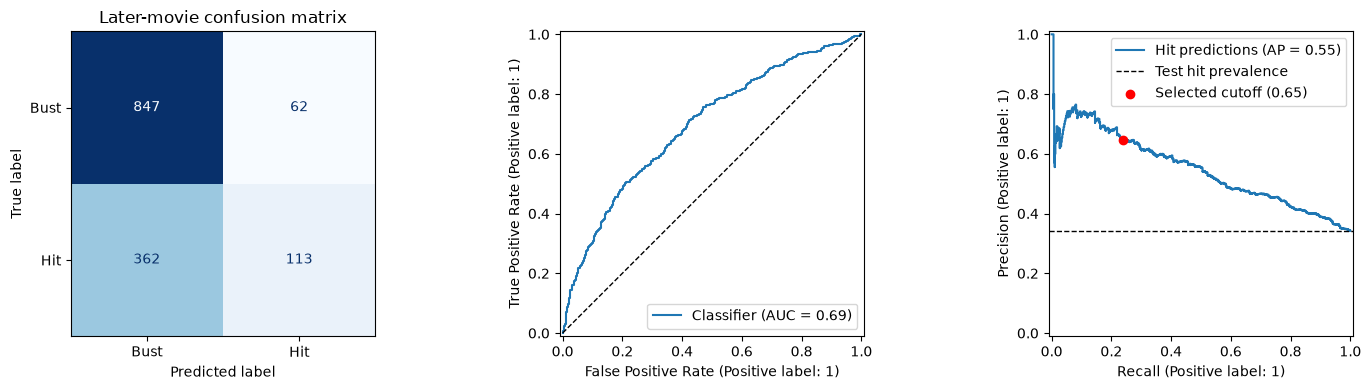

In [17]:
# Test movies with the final model's probability, prediction, and whether it was right
prediction_examples = movies.loc[test_mask, ["title_tmdb", "release_date", "success"]].copy()
prediction_examples["hit_probability"] = test_probability
prediction_examples["predicted_success"] = test_prediction
prediction_examples["correct"] = prediction_examples["success"].eq(test_prediction)
display(prediction_examples.head(10).round({"hit_probability": 3}))   # round only the probability column

# Confusion matrix, ROC curve, and precision-recall curve for the final model on the test movies
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, labels=[0, 1], display_labels=["Bust", "Hit"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Later-movie confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[1], name="Classifier")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[2], name="Hit predictions")
axes[2].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label="Test hit prevalence")
# Mark where the selected cutoff sits on the precision-recall curve
selected_precision = precision_score(y_test, test_prediction, zero_division=0)
selected_recall = recall_score(y_test, test_prediction, zero_division=0)
axes[2].scatter(selected_recall, selected_precision, color="red", zorder=3, label=f"Selected cutoff ({selected_threshold:.2f})")
axes[2].legend()
plt.tight_layout()
plt.show()

### Most confident wrong predictions
This table lists the test movies on which the final model was most wrong, namely the busts it rated most likely to be hits and the hits it rated least likely to be hits. It is for inspection only, and nothing here is used to choose settings, features, or the cutoff.

In [18]:
# The test movies on which the final model was most wrong
# Busts with the highest predicted probability of being a hit
most_confident_false_hits = prediction_examples.loc[prediction_examples["success"] == 0].sort_values("hit_probability", ascending=False, kind="stable").head(5)

# Hits with the lowest predicted probability of being a hit
most_confident_missed_hits = prediction_examples.loc[prediction_examples["success"] == 1].sort_values("hit_probability", ascending=True, kind="stable").head(5)

display_columns = ["title_tmdb", "release_date", "success", "hit_probability", "predicted_success"]
print("Busts the model rated most likely to be hits")
display(most_confident_false_hits[display_columns].round({"hit_probability": 3}))
print("Hits the model rated least likely to be hits")
display(most_confident_missed_hits[display_columns].round({"hit_probability": 3}))

Busts the model rated most likely to be hits


,title_tmdb,release_date,success,hit_probability,predicted_success
6165,An Egg Rescue,2021-08-12,0,0.912,1
6801,Mission: Impossible - The Final Reckoning,2025-05-17,0,0.896,1
6139,The Boss Baby: Family Business,2021-07-01,0,0.892,1
6132,Flee,2021-06-17,0,0.887,1
6457,Indiana Jones and the Dial of Destiny,2023-06-25,0,0.862,1


Hits the model rated least likely to be hits


,title_tmdb,release_date,success,hit_probability,predicted_success
6866,Prisoner of War,2025-09-19,1,0.081,0
6492,Fallen Leaves,2023-09-14,1,0.086,0
6039,The Eight Hundred,2020-08-14,1,0.091,0
6517,There's Still Tomorrow,2023-10-26,1,0.114,0
5918,While at War,2019-09-27,1,0.119,0


## 7. Compare feature groups within training
Use three expanding chronological validation splits, identical across models and feature versions. Fresh preprocessing is fitted for every fold. Training dates precede validation dates in each split. Compare mean validation ROC AUC, macro F1, and balanced accuracy. Only training movies are used, and no feature version is selected using the later test data, although this section appears after the test results.

The comparisons are cumulative: movie characteristics, plus director history, plus actor history, then company history. They do not isolate individual transformations or prove causation.

This section retains the original estimator settings to isolate the cumulative feature comparison. It does not retune each feature version. The tuning section above searches settings using all features. Its selection score is not an independent estimate after selection.

In [19]:
# The same cumulative feature groups as Section 4b, compared here with the initial settings only
movie_features = (
    ["runtime", "log_budget", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p"]
company_franchise_features = ["company_films_5yr_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
# Keep only the groups chosen in the Tuning controls, and check that All features matches the predictor list
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

In [20]:
# Split unique dates so equal release dates never appear on both sides.
training_dates = movies.loc[train_mask, "release_date"]
unique_dates = np.sort(training_dates.unique())
validation_splits = []
split_details = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_dates), 1):
    fit_indices = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_indices = training_dates.index[training_dates.isin(unique_dates[later])]
    assert movies.loc[fit_indices, "release_date"].max() < movies.loc[validation_indices, "release_date"].min()
    assert set(fit_indices).isdisjoint(validation_indices)
    assert set(fit_indices).union(validation_indices).issubset(set(X_train.index))
    validation_splits.append((fold, fit_indices, validation_indices))
    split_details.append({
        "Fold": fold, "Training movies": len(fit_indices), "Validation movies": len(validation_indices),
        "Training ends": movies.loc[fit_indices, "release_date"].max().date(),
        "Validation starts": movies.loc[validation_indices, "release_date"].min().date(),
        "Validation ends": movies.loc[validation_indices, "release_date"].max().date(),
    })
display(pd.DataFrame(split_details))

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,1329,1427,1999-12-03,1999-12-10,2006-11-01
1,2,2756,1384,2006-11-01,2006-11-02,2012-03-12
2,3,4140,1395,2012-03-12,2012-03-14,2017-11-17


In [21]:
# Fit each feature group on each validation fold with the initial settings and a 0.5 cutoff
comparison_rows = []
for version, columns in feature_versions.items():
    for fold, fit_indices, validation_indices in validation_splits:
        assert y_train.loc[fit_indices].nunique() == 2
        assert y_train.loc[validation_indices].nunique() == 2
        candidate = make_classifier(columns)
        candidate.fit(X_train.loc[fit_indices, columns], y_train.loc[fit_indices])
        probability = candidate.predict_proba(X_train.loc[validation_indices, columns])[:, list(candidate.classes_).index(1)]
        predicted = (probability >= BASE_THRESHOLD).astype(int)
        metrics = classification_scores(version, "Validation", y_train.loc[validation_indices], predicted, probability)
        comparison_rows.append({"Version": version, "Fold": fold, "Predictors": len(columns), **{key: value for key, value in metrics.items() if key not in ["Model", "Split"]}})
# Average across the folds and show ROC AUC fold by fold
feature_fold_results = pd.DataFrame(comparison_rows)
feature_comparison = feature_fold_results.groupby("Version", sort=False).agg(
    Predictors=("Predictors", "first"),
    Validation_AUC=("ROC AUC", "mean"), AUC_std=("ROC AUC", "std"),
    Validation_macro_F1=("Macro F1", "mean"),
    Validation_hit_F1=("Hit F1", "mean"),
    Validation_hit_precision=("Hit precision", "mean"),
    Validation_hit_recall=("Hit recall", "mean"),
    Validation_balanced_accuracy=("Balanced accuracy", "mean"),
    Validation_accuracy=("Accuracy", "mean"),
)
display(feature_comparison.round(4))
display(feature_fold_results.pivot(index="Version", columns="Fold", values="ROC AUC").reindex(feature_versions).round(4))
assert len(feature_fold_results) == len(feature_versions) * N_VALIDATION_SPLITS

,Predictors,Validation_AUC,AUC_std,Validation_macro_F1,Validation_hit_F1,Validation_hit_precision,Validation_hit_recall,Validation_balanced_accuracy,Validation_accuracy
Version,,,,,,,,,
Movie characteristics,25,0.6612,0.0282,0.5536,0.3417,0.5984,0.2402,0.5724,0.6558
+ Director history,31,0.6735,0.0297,0.5840,0.4029,0.6023,0.3045,0.5920,0.6648
+ Actor history,32,0.6740,0.0283,0.5857,0.4057,0.6037,0.3072,0.5934,0.6660
All features,33,0.6740,0.0297,0.5869,0.4085,0.6017,0.3107,0.5940,0.6658


Fold,1,2,3
Version,,,
Movie characteristics,0.6286,0.6781,0.6769
+ Director history,0.6393,0.6911,0.6901
+ Actor history,0.6413,0.6892,0.6914
All features,0.6397,0.6907,0.6915


## Interpretation and limits
Financial histories use only earlier years and update through time, representing rolling predictions rather than a single forecast at the split date. Retrospective sources do not prove when earlier movies' final outcomes became known. The cohort excludes missing financial values and applies cleaning floors. Results do not represent all movies.

The movies were collected from TMDB by their current vote count, keeping only movies with at least 100 votes, and vote count is known only after release. Movies that performed poorly are therefore likely under-represented, so these results may not carry over to every film a studio considers.

The test period includes a large change in outcomes. The share of movies that were hits was 43.5% in 2017-2019, 24.3% in 2020-2022, and 34.3% in 2023-2025 (Section 5). The cutoff was chosen on earlier years, and hit precision fell to 0.500 in 2020-2022, so future periods with unusual hit rates may also see lower precision at a fixed cutoff.

Budgets and revenues are reported in nominal dollars and are not adjusted for inflation. The target is unaffected, because it compares revenue and budget for the same film, but `log_budget` places films from different years on the same nominal scale, and the model cannot correct for this because `release_year` is not a predictor.

Section 4 selects estimator settings using training-period validation. Section 4b additionally selects a threshold using training-period validation. Original and settings-only results retain the 0.5 threshold. Compare financial classifiers with one another using the same metrics and splits, not with rating-model MAE/R². Do not repeatedly tune using the already-inspected test period.

The current selection rule picks settings by validation ROC AUC, then picks the cutoff by hit F1 subject to a mean validation precision guard. Hit F1 alone is a low bar here, because the always-hit baseline scores 0.511 on the later test movies with no skill, so ROC AUC, average precision, and precision among the top-ranked movies are better evidence of usefulness and are the headline results in Section 5. Report hit precision, recall, and F1 together. Do not describe F1 itself as giving precision extra weight. The 0.70 requirement is the shared starting rule for every success model, so that the models are compared under the same rule, and a lower precision requirement of 65% may be tested after that comparison and applied to every model.

## Refresh the visualization report
This final cell saves metrics and prediction summaries for [the visualization notebook](../../Data_visualization/model_visualizations.ipynb). It does not write or modify dataset CSVs. Save this notebook before running all cells so report freshness checks match the code.

In [22]:
# Save this notebook's metrics and predictions for the visualization notebook
from pathlib import Path
import importlib.util

report_module_path = Path("../../Data_visualization/model_reports.py")
report_spec = importlib.util.spec_from_file_location("project_model_reports", report_module_path)
report_tools = importlib.util.module_from_spec(report_spec)
report_spec.loader.exec_module(report_tools)
report_path = report_tools.save_model_report(globals(), Path("logistic_regression.ipynb"))
print("Visualization report saved:", report_path)

Visualization report saved: /Users/shuvamchowdhury/Documents/UVA/FALL 26/DS 6021/DS6021_Group2_FinalProject/Data_visualization/results/success/logistic_regression.json
